# Lab 4 — Build the Audience, Then Buy It
Name: Igor Protoriev | Group: KM-41

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab4-tv-audiences/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")
survey = pd.read_csv(f"{DATA}/purchase_survey.txt", sep="\t", dtype=str, keep_default_na=False)
survey_layout = pd.read_csv(f"{DATA}/purchase_survey_layout.txt", sep="\t", dtype=str)
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")
universe = pd.read_parquet(f"{DATA}/universe.parquet")

In [2]:
START, END = pd.Timestamp("2024-10-01"), pd.Timestamp("2024-10-31")


def broadcast_day(ts):
    """A broadcast day runs 06:00-05:59: 01:00 on Oct 15 belongs to Oct 14."""
    return (ts - pd.Timedelta(hours=6)).dt.normalize()


programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])
programs["minutes"] = (programs["end_ts"] - programs["start_ts"]).dt.total_seconds() / 60

dw = daily_weights[daily_weights["resp_type"].isin(["R", "L"])].copy()
dw["broadcast_date"] = pd.to_datetime(dw["broadcast_date"])
dw = dw[dw["broadcast_date"].between(START, END)]

person_ids = viewer_attributes.loc[viewer_attributes["attr_id"].isin([101, 102]), "respondent_id"].unique()
age = viewer_attributes[viewer_attributes["attr_id"] == 300].drop_duplicates("respondent_id").set_index("respondent_id")["value"]
female = viewer_attributes.loc[viewer_attributes["attr_id"] == 202, "respondent_id"]
people = pd.DataFrame(index=pd.Index(person_ids, name="respondent_id"))
people["age"] = age
people["sex"] = "Men"
people.loc[people.index.isin(female), "sex"] = "Women"
adults = people[people["age"] >= 18].copy()
print("R and L people:", len(people), "| adults 18+:", len(adults))

R and L people: 10216 | adults 18+: 8010


## Task 1.0 — Clean the survey file

In [3]:
lay = survey_layout.copy()
lay["KEYWORD"] = lay["KEYWORD"].str.strip().str.upper()
lay["RECTYPE"] = lay["RECTYPE"].str.strip()
lay["question"] = lay["Text"].where(lay["RECTYPE"] == "H").ffill()
codes = lay[lay["RECTYPE"] == "B"].copy()
codes["SAMPLE"] = pd.to_numeric(codes["SAMPLE"].str.replace(",", ""))


def pair_count(text):
    """'1 pair' -> 1, '2 pairs' -> 2, '3 or more' / '3+' -> 3, otherwise 0."""
    t = str(text).lower()
    for word, n in [("1", 1), ("one", 1), ("2", 2), ("two", 2), ("3", 3), ("three", 3)]:
        if word in t:
            return n
    return 0


codes["pairs"] = codes["Text"].apply(pair_count)
codes["kind"] = "brand"
codes.loc[codes["pairs"] > 0, "kind"] = "pairs"
codes.loc[codes["SAMPLE"].idxmax(), "kind"] = "any"
codes.loc[codes["kind"] != "pairs", "pairs"] = 0
display(codes[["KEYWORD", "Text", "Variable", "SAMPLE", "kind", "pairs"]])

ANY = codes.loc[codes["kind"] == "any", "KEYWORD"].iloc[0]
PAIR_CODES = codes.loc[codes["kind"] == "pairs"].set_index("KEYWORD")["pairs"]
BRANDS = codes.loc[codes["kind"] == "brand"].set_index("KEYWORD")["Text"]
KESTREL = codes.loc[(codes["Text"] + codes["Variable"].fillna("")).str.lower().str.contains("kestrel"), "KEYWORD"].iloc[0]

print("RESPID examples:", survey["RESPID"].sample(8, random_state=1).tolist())
print("KEYWORD values not in the layout:", sorted(set(survey["KEYWORD"]) - set(codes["KEYWORD"]))[:20])
print("VALUE counts:", survey["VALUE"].value_counts().to_dict())

s = survey.copy()
raw_id = s["RESPID"].str.strip()
s["id"] = pd.to_numeric(raw_id, errors="coerce")                                         
s["id"] = s["id"].fillna(pd.to_numeric(raw_id.str.replace(r"\D", "", regex=True), errors="coerce"))  
s["kw"] = s["KEYWORD"].str.strip().str.upper()
value = s["VALUE"].str.strip().str.upper()
s["yes"] = value.isin(["1", "1.0", "Y", "YES", "TRUE", "X", value.mode()[0]])   
adult_ids = set(adults.index)
problems = []

bad = s["id"].notna() & (s["RESPID"] != s["id"].round().astype("Int64").astype(str))
problems.append(["RESPID written differently (spaces, leading zeros, .0)", bad.sum(), "fixed: read as a number"])

bad = (s["KEYWORD"] != s["kw"]) & s["kw"].isin(codes["KEYWORD"])
problems.append(["KEYWORD with wrong case or spaces", bad.sum(), "fixed: stripped, upper case"])

bad = ~s["kw"].isin(codes["KEYWORD"])
problems.append(["KEYWORD not in the layout (or a question code)", bad.sum(), "dropped"])
s = s[~bad]

bad = ~s["yes"]
problems.append(["VALUE is not a yes", bad.sum(), "dropped"])
s = s[~bad]

bad = ~s["id"].isin(adult_ids)
problems.append(["RESPID is not an adult panel member (child, household, unknown, empty)", bad.sum(), "dropped"])
s = s[~bad]
s["id"] = s["id"].astype(int)

bad = s.duplicated(["id", "kw"])
problems.append(["Same person and KEYWORD twice", bad.sum(), "dropped the copy"])
s = s[~bad]

s["pairs"] = s["kw"].map(PAIR_CODES).fillna(0)
pair_rows = s[s["kw"].isin(PAIR_CODES.index)]
two_counts = pair_rows["id"].duplicated(keep=False)
keep = pair_rows.sort_values("pairs").drop_duplicates("id", keep="last").index
lower_count = pair_rows.index.difference(keep)
problems.append(["Person with two pair counts", two_counts.sum(), "kept the higher count"])
s = s.drop(lower_count)

per = pd.DataFrame(index=adults.index)
per["pairs"] = s.groupby("id")["pairs"].max().reindex(per.index).fillna(0).astype(int)
for code, name in BRANDS.items():
    per[name] = per.index.isin(s.loc[s["kw"] == code, "id"])
has_any = per.index.isin(s.loc[s["kw"] == ANY, "id"])
per["buyer"] = has_any | (per["pairs"] > 0) | per[list(BRANDS)].any(axis=1)
problems.append(["Pair count or brand but no Any row", (per["buyer"] & ~has_any).sum(), "counted as a buyer"])
per["pairs_group"] = per["pairs"].map({0: "0", 1: "1", 2: "2", 3: "3+"})

print("Survey data rows:", len(survey))
print("Clean yes answers:", len(s))
print("Adult panel members:", len(per))
print("Non-buyers:", (~per["buyer"]).sum())
print("People with two pair counts:", pair_rows.loc[two_counts, "id"].nunique())
display(pd.DataFrame(problems, columns=["bad record", "rows", "what I did"]))

check = codes[["KEYWORD", "Text", "SAMPLE"]].copy()
mine = s["kw"].value_counts()
mine[ANY] = per["buyer"].sum()
check["my count"] = check["KEYWORD"].map(mine).fillna(0).astype(int)
check["difference"] = check["my count"] - check["SAMPLE"]
display(check[["KEYWORD", "Text", "my count", "SAMPLE", "difference"]])

kestrel_name = BRANDS[KESTREL]
raw_kestrel = (survey["KEYWORD"] == KESTREL).sum()
raw_buyer_share = survey.loc[survey["KEYWORD"] == ANY, "RESPID"].nunique() / len(per)
print("Kestrel buyers, raw file vs clean:", raw_kestrel, "vs", per[kestrel_name].sum())
print("Share of buyers, raw file vs clean:", f"{raw_buyer_share:.3f}", "vs", f"{per['buyer'].mean():.3f}")

,KEYWORD,Text,Variable,SAMPLE,kind,pairs
2,X710100,Any,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,4779,any,0
3,X710101,1 pair,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,1810,pairs,1
4,X710102,2 pairs,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,1308,pairs,2
5,X710103,3 or more pairs,APPAREL > ATHLETIC SHOES > PAIRS BOUGHT LAST 1...,1661,pairs,3
7,X710201,STRIDE,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,1563,brand,0
8,X710202,KESTREL,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,354,brand,0
9,X710203,EASYWALK,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,1050,brand,0
10,X710298,OTHER BRAND,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,2739,brand,0
11,X710299,DON'T KNOW,APPAREL > ATHLETIC SHOES > BRANDS BOUGHT IN LA...,371,brand,0


RESPID examples: [' 10078001', '10030702', '10308301', '10292501', '10300802', '10248301', '10020401', '10159601']
KEYWORD values not in the layout: ['', 'KEYWORD', 'X710100 ', 'X710101 ', 'X710102 ', 'X710103 ', 'X710201 ', 'X710202 ', 'X710203 ', 'X710298 ', 'X710299 ', 'X880112', 'X880112 ', 'X880140', 'X880140 ', 'X880141', 'X880141 ', 'X902001', 'X902001 ', 'x710100']
VALUE counts: {'1': 16410, '1.0': 262, 'y': 246, 'TRUE': 241, '0': 237, 'Y': 228, 'yes': 217, '0.0': 129, 'N': 127, 'no': 126, '': 124, 'VALUE': 2}
Survey data rows: 18349
Clean yes answers: 15397
Adult panel members: 8010
Non-buyers: 3231
People with two pair counts: 113


,bad record,rows,what I did
0,"RESPID written differently (spaces, leading ze...",1456,fixed: read as a number
1,KEYWORD with wrong case or spaces,1059,"fixed: stripped, upper case"
2,KEYWORD not in the layout (or a question code),741,dropped
3,VALUE is not a yes,742,dropped
4,"RESPID is not an adult panel member (child, ho...",423,dropped
5,Same person and KEYWORD twice,933,dropped the copy
6,Person with two pair counts,226,kept the higher count
7,Pair count or brand but no Any row,238,counted as a buyer


,KEYWORD,Text,my count,SAMPLE,difference
2,X710100,Any,4779,4779,0
3,X710101,1 pair,1810,1810,0
4,X710102,2 pairs,1308,1308,0
5,X710103,3 or more pairs,1661,1661,0
7,X710201,STRIDE,1563,1563,0
8,X710202,KESTREL,354,354,0
9,X710203,EASYWALK,1050,1050,0
10,X710298,OTHER BRAND,2739,2739,0
11,X710299,DON'T KNOW,371,371,0


Kestrel buyers, raw file vs clean: 516 vs 354
Share of buyers, raw file vs clean: 0.548 vs 0.597


**Answer:** The vendor's file broke its own promises in several ways (table above):
ids written in different formats, keywords with wrong case or spaces, codes that are not answers in the layout,
answers that are not a yes, ids that are not adult panel members, duplicate answers and people with two pair counts.
Some buyers had a pair count or a brand but no Any row. After cleaning, every count matches the layout's SAMPLE
(difference 0). Used as delivered, the file would give 516 Kestrel buyers instead of 354 (46% too many) and a share
of buyers of 0.548 instead of 0.597 (about 5 points too low).

## Task 1.1 — Four definitions

Adults 18+ (M): 252.6
Shoe buyers (M): 148.1
Heavy buyers, 3+ pairs (M): 49.6
Kestrel buyers (M): 10.0
Adults 25-54 (M): 123.7
Kestrel buyers in panel (n): 354


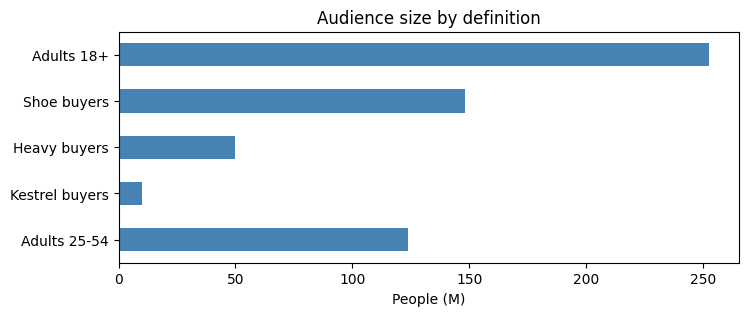

In [4]:
per["Adults 18+"] = True
per["Shoe buyers"] = per["buyer"]
per["Heavy buyers"] = per["pairs"] >= 3
per["Kestrel buyers"] = per[kestrel_name]
per["Adults 25-54"] = adults["age"].between(25, 54)
per["group"] = pd.cut(adults["age"], [17, 34, 54, 200], labels=["18-34", "35-54", "55+"]).astype(str) + " " + adults["sex"]
AUDS = ["Adults 18+", "Shoe buyers", "Heavy buyers", "Kestrel buyers", "Adults 25-54"]

dwa = dw.merge(per[AUDS + ["group"]], left_on="respondent_id", right_index=True)
DAYS = pd.date_range(START, END)


def audience_size(rows):
    """Average over the 31 broadcast days of the daily sum of weights."""
    return rows.groupby("broadcast_date")["weight"].sum().reindex(DAYS, fill_value=0).mean()

sizes = pd.Series({a: audience_size(dwa[dwa[a]]) for a in AUDS})
print("Adults 18+ (M):", round(sizes["Adults 18+"] / 1e6, 1))
print("Shoe buyers (M):", round(sizes["Shoe buyers"] / 1e6, 1))
print("Heavy buyers, 3+ pairs (M):", round(sizes["Heavy buyers"] / 1e6, 1))
print("Kestrel buyers (M):", round(sizes["Kestrel buyers"] / 1e6, 1))
print("Adults 25-54 (M):", round(sizes["Adults 25-54"] / 1e6, 1))
print("Kestrel buyers in panel (n):", per["Kestrel buyers"].sum())

(sizes / 1e6).plot(kind="barh", figsize=(8, 3), color="steelblue")
plt.xlabel("People (M)")
plt.title("Audience size by definition")
plt.gca().invert_yaxis()
plt.show()

## Task 1.2 — Who are they?

In [5]:
GROUPS = ["18-34 Men", "35-54 Men", "55+ Men", "18-34 Women", "35-54 Women", "55+ Women"]
share = pd.DataFrame({a: {g: audience_size(dwa[dwa[a] & (dwa["group"] == g)]) / sizes[a] for g in GROUPS} for a in AUDS})
index = (share.div(share["Adults 18+"], axis=0) * 100).round(0)
display(pd.concat({"share": share.round(3), "index vs adults": index}, axis=1))

share                                                       \
            Adults 18+ Shoe buyers Heavy buyers Kestrel buyers Adults 25-54   
18-34 Men        0.144       0.140        0.111          0.118        0.174   
35-54 Men        0.160       0.158        0.138          0.189        0.326   
55+ Men          0.185       0.186        0.189          0.126        0.000   
18-34 Women      0.144       0.140        0.139          0.181        0.174   
35-54 Women      0.160       0.178        0.226          0.265        0.326   
55+ Women        0.208       0.197        0.196          0.121        0.000   

            index vs adults                                          \
                 Adults 18+ Shoe buyers Heavy buyers Kestrel buyers   
18-34 Men             100.0        97.0         77.0           82.0   
35-54 Men             100.0        99.0         87.0          119.0   
55+ Men               100.0       101.0        102.0           68.0   
18-34 Women           100.0        98.0         97.0          126.0   
35-54 Women           100.0       111.0        142.0          166.0   
55+ Women             100.0        95.0         94.0           58.0   

                          
            Adults 25-54  
18-34 Men          121.0  
35-54 Men          204.0  
55+ Men              0.0  
18-34 Women        121.0  
35-54 Women        204.0  
55+ Women            0.0

**Answer:** For Kestrel I would hand the planner **heavy buyers (3+ pairs)**: it is a real
behaviour the brand cares about, it differs clearly from all adults (women 35–54 index 142, men 18–34 only 77),
and it is still big enough to measure in the panel (1,661 panelists). Kestrel buyers are closer to the brand but
far too few panelists (354), so their ratings would be mostly noise; adults 25–54 is easy to buy but does not
describe the buyers.

"Athletic-shoe buyers" looks almost like all adults because most adults buy at least one pair a year: when an
audience covers most of the population, its profile can only be the population's profile (every index near 100).

A limit of fused data: buying was attached to panelists **only through their demographics**, so it cannot tell us
whether buyers really watch a program more than other people of the same age, sex and income. Any "program for
shoe buyers" is just the program's demographic profile in disguise.

## Task 2.1 — Programs by audience

In [6]:
pv = viewings[viewings["resp_type"].isin(["R", "L"])]
view_by_net = {net: d for net, d in pv.groupby("network_code")}

people_day = dw.merge(per[AUDS], left_on="respondent_id", right_index=True, how="left")
people_day[AUDS] = people_day[AUDS].eq(True)
people_day["Persons 2+"] = True
ALL_AUDS = AUDS + ["Persons 2+"]
day_sizes = pd.DataFrame({a: people_day[people_day[a]].groupby("broadcast_date")["weight"].sum() for a in ALL_AUDS})
weights_by_day = {d: g.set_index("respondent_id") for d, g in people_day.groupby("broadcast_date")}


def rate(telecasts):
    """Average-minute viewers and rating of each telecast for every audience."""
    rows = []
    for t in telecasts.itertuples():
        v = view_by_net[t.network_code]
        v = v[(v["start_ts"] < t.end_ts) & (v["end_ts"] > t.start_ts)]
        mins = (v["end_ts"].clip(upper=t.end_ts) - v["start_ts"].clip(lower=t.start_ts)).dt.total_seconds() / 60
        mins = mins.groupby(v["respondent_id"]).sum().rename("mins")
        w = weights_by_day[t.broadcast_date].join(mins, how="inner")
        row = {"telecast_id": t.telecast_id}
        for a in ALL_AUDS:
            viewers = (w["weight"] * w["mins"] * w[a]).sum() / t.minutes
            row[a + " viewers"] = viewers
            row[a + " rating"] = viewers / day_sizes.loc[t.broadcast_date, a] * 100
        rows.append(row)
    return telecasts.merge(pd.DataFrame(rows), on="telecast_id")


def to_minutes(hhmm):
    """Broadcast clock 'HH:MM' -> minutes since 06:00 (25:37 -> 25*60 + 37 - 360)."""
    h, m = hhmm.split(":")
    return int(h) * 60 + int(m) - 360


def price(telecasts):
    t = telecasts[["telecast_id", "network_code", "program_name", "start_ts"]].copy()
    shifted = t["start_ts"] - pd.Timedelta(hours=6)
    t["b_weekday"] = shifted.dt.dayofweek
    t["b_minute"] = shifted.dt.hour * 60 + shifted.dt.minute
    program_rows = rate_card[rate_card["program_name"].notna()]
    by_program = t.merge(program_rows[["network_code", "program_name", "cost_30s_usd"]], on=["network_code", "program_name"])
    time_rows = rate_card[rate_card["program_name"].isna()].copy()
    time_rows["start_min"] = time_rows["start_time"].apply(to_minutes)
    time_rows["end_min"] = time_rows["end_time"].apply(to_minutes)
    time_rows = time_rows.explode("weekdays")
    time_rows["b_weekday"] = time_rows["weekdays"].astype(int)
    rest = t[~t["telecast_id"].isin(by_program["telecast_id"])]
    by_time = rest.merge(time_rows[["network_code", "b_weekday", "start_min", "end_min", "cost_30s_usd"]], on=["network_code", "b_weekday"])
    by_time = by_time[(by_time["start_min"] <= by_time["b_minute"]) & (by_time["b_minute"] < by_time["end_min"])]
    both = pd.concat([by_program, by_time]).drop_duplicates("telecast_id")
    return telecasts.merge(both[["telecast_id", "cost_30s_usd"]], on="telecast_id", how="left")


PICKS = [("Sunday Night Football", "NBC", "NFL Football"), ("Monday Night Football", "ABC", "NFL Football"),
         ("Dancing with the Stars", "ABC", "Dancing with the Stars"), ("NCIS", "CBS", "NCIS"),
         ("Hannity", "FNC", "Hannity"), ("Unsellable Houses", "HGTV", "Unsellable Houses"),
         ("Halloween Wars", "FOOD", "Halloween Wars"), ("Grotesquerie", "FX", "Grotesquerie")]
prime_oct = programs[(programs["daypart"] == "Prime") & programs["broadcast_date"].between(START, END)]
parts = []
for label, net, name in PICKS:
    t = prime_oct[(prime_oct["network_code"] == net) & (prime_oct["program_name"].str.lower() == name.lower())].copy()
    if len(t) == 0:
        print("No prime-time telecasts found for", label, "- check the name in programs")
    t["program"] = f"{label} ({net})"
    parts.append(t)
t2_telecasts = price(rate(pd.concat(parts)))

t2 = t2_telecasts.groupby("program", sort=False).agg(
    telecasts=("telecast_id", "size"), adults_rating=("Adults 18+ rating", "mean"),
    target_rating=("Heavy buyers rating", "mean"), adult_viewers=("Adults 18+ viewers", "mean"),
    target_viewers=("Heavy buyers viewers", "mean"), kestrel_rating=("Kestrel buyers rating", "mean"),
    cost_30s=("cost_30s_usd", "mean"))
t2["composition"] = t2["target_viewers"] / t2["adult_viewers"]
t2["index"] = t2["target_rating"] / t2["adults_rating"] * 100
t2["adults_cpm"] = t2["cost_30s"] / t2["adult_viewers"] * 1000
t2["target_cpm"] = t2["cost_30s"] / t2["target_viewers"] * 1000
t2["kestrel_index"] = t2["kestrel_rating"] / t2["adults_rating"] * 100

show = pd.DataFrame({
    "telecasts": t2["telecasts"],
    "adults rating": t2["adults_rating"].round(2),
    "target rating": t2["target_rating"].round(2),
    "target viewers (000)": (t2["target_viewers"] / 1000).round(0).astype(int),
    "composition": t2["composition"].round(3),
    "index": t2["index"].round(0).astype(int),
    "cost per :30 ($)": t2["cost_30s"].round(0).astype(int),
    "adults CPM ($)": t2["adults_cpm"].round(0).astype(int),
    "target CPM ($)": t2["target_cpm"].round(0).astype(int),
})
display(show)
print("Target universe (M):", round(sizes["Heavy buyers"] / 1e6, 1))

,telecasts,adults rating,target rating,target viewers (000),composition,index,cost per :30 ($),adults CPM ($),target CPM ($)
program,,,,,,,,,
Sunday Night Football (NBC),4,5.82,5.79,2865,0.195,99,487200,33,170
Monday Night Football (ABC),3,8.93,8.36,4149,0.184,94,723600,32,174
Dancing with the Stars (ABC),9,3.25,3.14,1564,0.191,97,158600,19,101
NCIS (CBS),3,2.21,2.43,1206,0.216,110,178800,32,148
Hannity (FNC),22,1.09,0.84,417,0.152,77,39900,15,96
Unsellable Houses (HGTV),13,0.50,0.64,317,0.249,127,12900,10,41
Halloween Wars (FOOD),9,0.28,0.33,162,0.228,116,9700,14,60
Grotesquerie (FX),25,0.26,0.25,124,0.188,96,7592,11,61


Target universe (M): 49.6


## Task 2.2 — Index, volume or price?

In [7]:
print("Highest index (program):", t2["index"].idxmax())
print("Most target viewers (program):", t2["target_viewers"].idxmax())
print("Lowest target CPM (program):", t2["target_cpm"].idxmin())

Highest index (program): Unsellable Houses (HGTV)
Most target viewers (program): Monday Night Football (ABC)
Lowest target CPM (program): Unsellable Houses (HGTV)


**Answer:** Unsellable Houses (HGTV) has the highest index (127) and the lowest target CPM ($41), while
Monday Night Football (ABC) delivers the most target viewers (4,149 thousand). The three winners are not the same
program: the most concentrated and cheapest audience is on a small cable show, the biggest one is on a broadcast game.
The highest index only says that the program's audience is *concentrated* in heavy buyers; it says
nothing about how many of them it delivers or what they cost. A small cable show can have a high index and still
deliver few target viewers (317 thousand for Unsellable Houses), while a big broadcast program with an index near 100
delivers many times more heavy buyers. As in the shampoo example of Lecture 5, I would tell the client that we buy
**target viewers at the lowest target CPM** within the reach we need: index is a tie-breaker and a sign of waste,
not the goal. Buying "only the highest index" would leave most heavy buyers unreached and could cost more per
heavy buyer.

## Task 2.3 — Kestrel buyers

In [8]:
display(pd.DataFrame({"heavy-buyer index": t2["index"].round(0).astype(int),
                      "Kestrel index": t2["kestrel_index"].round(0).astype(int)}))

,heavy-buyer index,Kestrel index
program,,
Sunday Night Football (NBC),99,99
Monday Night Football (ABC),94,86
Dancing with the Stars (ABC),97,83
NCIS (CBS),110,57
Hannity (FNC),77,43
Unsellable Houses (HGTV),127,77
Halloween Wars (FOOD),116,95
Grotesquerie (FX),96,130


**Answer:** The Kestrel index jumps around because only 354 Kestrel buyers are in the panel (against 1,661
heavy buyers). On one telecast only a handful of them watch, so one or two panelists more or less change the
rating a lot (sampling error grows as the in-target sample shrinks, Lecture 6). The heavy-buyer index rests on
many more panelists, so it is far more stable. I would trust the **heavy-buyer index**. To check: look at the
number of Kestrel panelists behind each rating, compute standard errors or bootstrap the panelists, and compare
the index across the separate October telecasts of each program (or across months): a real skew repeats, noise
does not.

## Task 3.1 — Weights

In [9]:
def to_eastern(ts):
    """UTC timestamps -> naive US Eastern (handles DST)."""
    ts = pd.to_datetime(ts)
    if ts.dt.tz is None:
        ts = ts.dt.tz_localize("UTC")
    return ts.dt.tz_convert("America/New_York").dt.tz_localize(None)

acr = acr_sessions.copy()
acr["start_et"] = to_eastern(acr["start_utc"])
acr["end_et"] = to_eastern(acr["end_utc"])
acr["broadcast_date"] = broadcast_day(acr["start_et"])
acr = acr[(acr["end_et"] - acr["start_et"]) >= pd.Timedelta(minutes=1)]
live = acr[acr["session_type"] == "live"]

tvs = acr_sessions.drop_duplicates("tv_id")[["tv_id", "hashed_ip"]]
hh_per_ip = hh_attributes.groupby("hashed_ip")["household_id"].nunique()
one_hh = hh_attributes[hh_attributes["hashed_ip"].map(hh_per_ip) == 1]
matched = tvs.merge(one_hh, on="hashed_ip")
matched["is65"] = matched["head_age_band"] == "65+"

uni = universe.copy()
uni["is65"] = uni["head_age"].str.contains(r"65\+|65 and|over", case=False)

intab = acr[["tv_id", "broadcast_date"]].drop_duplicates().merge(matched[["tv_id", "is65", "income_band"]], on="tv_id")
cell_n = intab.groupby(["broadcast_date", "is65", "income_band"]).size().rename("n_tvs").reset_index()
cell_n = cell_n.merge(uni[["is65", "income_band", "tv_households"]], on=["is65", "income_band"])
cell_n["tv_weight"] = cell_n["tv_households"] / cell_n["n_tvs"]
intab = intab.merge(cell_n[["broadcast_date", "is65", "income_band", "tv_weight"]], on=["broadcast_date", "is65", "income_band"])
day_sums = intab.groupby("broadcast_date")["tv_weight"].sum()

print("TVs matched to one household:", len(matched))
print("Weights sum per day (M):", round(day_sums.min() / 1e6, 1), "to", round(day_sums.max() / 1e6, 1),
      "| universe:", round(uni["tv_households"].sum() / 1e6, 1))


def tv_watchers(t):
    """TVs whose live sessions on the telecast's network overlap it by at least 1 minute (in total)."""
    v = live[(live["network_code"] == t.network_code) & (live["start_et"] < t.end_ts) & (live["end_et"] > t.start_ts)]
    overlap = (v["end_et"].clip(upper=t.end_ts) - v["start_et"].clip(lower=t.start_ts)).dt.total_seconds() / 60
    mins = overlap.groupby(v["tv_id"]).sum()
    return mins[mins >= 1].index


ref = reference_ratings.merge(programs, on="telecast_id")
rows = []
for t in ref.itertuples():
    day = intab[intab["broadcast_date"] == t.broadcast_date]
    watched = day["tv_id"].isin(tv_watchers(t))
    rows.append({"telecast": f"{t.program_name} ({t.network_code})", "date": t.broadcast_date.strftime("%Y-%m-%d"),
                 "unweighted": 100 * watched.mean(),
                 "weighted": 100 * day.loc[watched, "tv_weight"].sum() / day["tv_weight"].sum(),
                 "reference": t.hh_rating})
t3 = pd.DataFrame(rows)
t3["moved"] = t3["weighted"] - t3["unweighted"]
display(t3.round(2))

gap_u = (t3["reference"] - t3["unweighted"]).abs().mean()
gap_w = (t3["reference"] - t3["weighted"]).abs().mean()
print("Mean gap unweighted (points):", round(gap_u, 2))
print("Mean gap weighted (points):", round(gap_w, 2))
print("Share of gap closed:", round((gap_u - gap_w) / gap_u, 3))

TVs matched to one household: 19607
Weights sum per day (M): 125.8 to 125.8 | universe: 125.8


,telecast,date,unweighted,weighted,reference,moved
0,MLB Postseason (FOX),2024-10-25,17.03,17.76,25.86,0.72
1,NFL Football (NBC),2024-10-27,22.62,23.75,33.14,1.13
2,NCIS (CBS),2024-10-14,5.50,5.80,10.56,0.29
3,Hannity (FNC),2024-10-16,1.04,1.35,2.30,0.31
4,Unsellable Houses (HGTV),2024-10-16,2.12,2.08,3.69,-0.04
5,Halloween Baking Championship (FOOD),2024-10-14,0.95,0.90,1.63,-0.05
6,Grotesquerie (FX),2024-10-16,2.17,2.11,3.53,-0.06
7,The Real Housewives of New York City (BRAVO),2024-10-15,0.71,0.64,1.23,-0.07


Mean gap unweighted (points): 3.73
Mean gap weighted (points): 3.44
Share of gap closed: 0.075


## Task 3.2 — What weighting cannot fix
**Answer:** Weighting raised the ratings of programs with older audiences, because 65+ homes are
under-represented in the footprint and now get bigger weights. In points the big sports telecasts moved most
(NFL Football (NBC) +1.13, MLB Postseason (FOX) +0.72); relative to its rating Hannity (FNC) moved most
(+0.31 on 1.04, about +30%), and NCIS (CBS) went up by 0.29. Programs with younger audiences moved a little down
(Grotesquerie (FX) −0.06, The Real Housewives of New York City (BRAVO) −0.07). But most of the gap is still there:
weighting closed only 7.5% of it (mean gap 3.73 → 3.44 points). Weighting can only fix *who* is in the sample,
by the variables we weight on. It cannot fix what the TV does not see: one set out of about 2.6 in the home,
viewing hidden in apps, streaming devices and unknown sessions, and the TVs that could not be matched (Lab 3).
It also cannot fix differences inside a cell: opted-in homes may watch differently from other homes with the same
age and income (Lecture 4). Income barely moves the ratings because, within an age group, these programs are
watched about equally by low- and high-income homes: if the viewing rate hardly differs between cells,
re-weighting the cells cannot change the average.

## Task 4.1 — October predicts October

Telecasts forecast (n): 101
MAPE, P2+ (%): 35.8
MAPE, heavy buyers (%): 38.6
Biggest miss, P2+ (program, date): Krapopolis (FOX), 2024-10-27


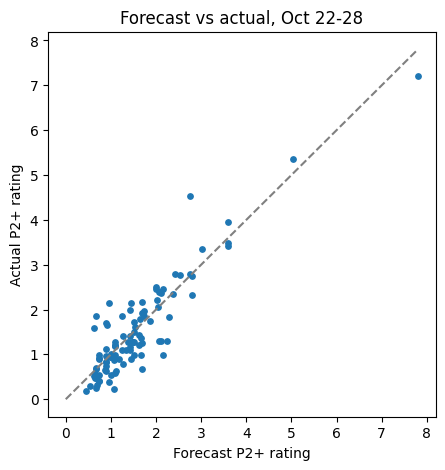

In [10]:
BIG5 = ["CBS", "NBC", "ABC", "FOX", "FNC"]
prime5 = programs[(programs["daypart"] == "Prime") & programs["network_code"].isin(BIG5)
                  & programs["broadcast_date"].between(START, pd.Timestamp("2024-10-28"))]
history = prime5[prime5["broadcast_date"] <= "2024-10-21"]
week = prime5[prime5["broadcast_date"] >= "2024-10-22"]
week = week.merge(history[["network_code", "program_name"]].drop_duplicates(), on=["network_code", "program_name"])

hist_r = rate(history)
week_r = rate(week)
fc = hist_r.groupby(["network_code", "program_name"])[["Persons 2+ rating", "Heavy buyers rating"]].mean()
fc.columns = ["forecast P2+", "forecast heavy"]
t4 = week_r.merge(fc, on=["network_code", "program_name"])
t4["program"] = t4["program_name"] + " (" + t4["network_code"] + ")"
t4["date"] = t4["broadcast_date"].dt.strftime("%Y-%m-%d")
t4["error P2+"] = (t4["Persons 2+ rating"] - t4["forecast P2+"]).abs() / t4["Persons 2+ rating"]
t4["error heavy"] = (t4["Heavy buyers rating"] - t4["forecast heavy"]).abs() / t4["Heavy buyers rating"]
mape_p2 = t4.loc[t4["Persons 2+ rating"] > 0, "error P2+"].mean() * 100
mape_heavy = t4.loc[t4["Heavy buyers rating"] > 0, "error heavy"].mean() * 100
worst = t4[t4["Persons 2+ rating"] > 0].sort_values("error P2+", ascending=False)

print("Telecasts forecast (n):", len(t4))
print("MAPE, P2+ (%):", round(mape_p2, 1))
print("MAPE, heavy buyers (%):", round(mape_heavy, 1))
print("Biggest miss, P2+ (program, date):", worst["program"].iloc[0] + ",", worst["date"].iloc[0])

plt.figure(figsize=(5, 5))
plt.scatter(t4["forecast P2+"], t4["Persons 2+ rating"], s=15)
top = max(t4["forecast P2+"].max(), t4["Persons 2+ rating"].max())
plt.plot([0, top], [0, top], color="gray", linestyle="--")
plt.xlabel("Forecast P2+ rating")
plt.ylabel("Actual P2+ rating")
plt.title("Forecast vs actual, Oct 22-28")
plt.show()

## Task 4.2 — Why it missed

In [11]:
display(worst.head(5)[["program", "date", "forecast P2+", "Persons 2+ rating", "error P2+"]]
        .rename(columns={"Persons 2+ rating": "actual P2+"}).round(2))

,program,date,forecast P2+,actual P2+,error P2+
80,Krapopolis (FOX),2024-10-27,1.06,0.22,3.88
78,Universal Basic Guys (FOX),2024-10-27,0.68,0.26,1.62
37,Fire Country (CBS),2024-10-27,1.70,0.67,1.55
65,Accused (FOX),2024-10-22,0.95,0.37,1.55
4,What Would You Do? (ABC),2024-10-23,0.44,0.18,1.38


**Answer:** Three of the five biggest misses aired on Sunday, 2024-10-27, when the NFL games ran long: in
programs FOX starts prime with local programming at 19:15, CBS starts 60 Minutes at 19:35 and its next shows begin
at :44. The whole night moved, the lead-ins changed, and Krapopolis (FOX) and Fire Country (CBS) aired twice that
night, so one of the telecasts was a late second airing with a much smaller audience than the history average.
Accused (FOX, 2024-10-22) and What Would You Do? (ABC, 2024-10-23) show no schedule change in programs; their drop
is more likely a repeat episode or stronger competition. An average of past weeks cannot know any of that.
The heavy-buyer forecast is less accurate (MAPE 38.6% vs 35.8% for persons 2+) because far fewer panelists are in
the target: each rating rests on a small sample, so both the history average and the actual rating are noisy, and
MAPE grows as the in-target sample shrinks (Lecture 6). Small target ratings also make each relative error larger.
A better forecast would use (1) the schedule: what airs before and against the program, special events, game
match-ups and expected run times; (2) more history and trend, e.g. the same week last year, season-to-date with
more weight on recent weeks, and P2+ ratings combined with a stable audience composition instead of the noisy
target rating alone.

## Task 5.1 — The plan

In [12]:
BUDGET = 1_000_000
plan = t2[["telecasts", "cost_30s", "target_viewers", "adult_viewers", "target_cpm"]].copy()
plan["max spots"] = ((plan["telecasts"] / 31 * 7).round().clip(lower=1) * 2).astype(int)
plan = plan.sort_values("target_cpm")
left = BUDGET
spots = []
for cost, most in zip(plan["cost_30s"], plan["max spots"]):
    n = int(min(most, left // round(cost)))
    spots.append(n)
    left -= n * round(cost)
plan["spots"] = spots
plan["cost"] = plan["spots"] * plan["cost_30s"].round()
plan["target impressions"] = plan["spots"] * plan["target_viewers"]
plan["adult impressions"] = plan["spots"] * plan["adult_viewers"]
plan = plan[plan["spots"] > 0]
display(pd.DataFrame({"spots": plan["spots"], "cost ($)": plan["cost"].astype(int),
                      "target impressions (M)": (plan["target impressions"] / 1e6).round(1),
                      "target CPM ($)": plan["target_cpm"].round(0).astype(int)}))
print("Plan cost ($):", int(plan["cost"].sum()))
print("Plan target impressions (M):", round(plan["target impressions"].sum() / 1e6, 1))
print("Plan target CPM ($):", round(plan["cost"].sum() / plan["target impressions"].sum() * 1000))
print("Plan composition (heavy buyers / adults):", round(plan["target impressions"].sum() / plan["adult impressions"].sum(), 3))

,spots,cost ($),target impressions (M),target CPM ($)
program,,,,
Unsellable Houses (HGTV),6,77400,1.9,41
Halloween Wars (FOOD),4,38800,0.6,60
Grotesquerie (FX),12,91104,1.5,61
Hannity (FNC),10,399000,4.2,96
Dancing with the Stars (ABC),2,317200,3.1,101


Plan cost ($): 923504
Plan target impressions (M): 11.3
Plan target CPM ($): 81
Plan composition (heavy buyers / adults): 0.182


## Task 5.2 — Recommendation
**Answer:** I recommend spending the $1,000,000 on Unsellable Houses (HGTV, 6 spots), Halloween Wars (FOOD, 4),
Grotesquerie (FX, 12), Hannity (FNC, 10) and Dancing with the Stars (ABC, 2), chosen by the lowest cost per heavy
buyer (target CPM), with at most two spots per telecast so the same viewers are not hit again and again.
The plan costs $923,504 and should deliver about 11.3M heavy-buyer impressions, an average target CPM of $81;
the remaining $76,496 is too little for one more spot within that limit (a :30 in NCIS costs $178,800).
High-index programs are kept where they are also cheap per heavy buyer (Unsellable Houses, index 127), while
Hannity (index 77) and Dancing with the Stars (index 97) are bought for volume at a low target CPM.
Delivery is uncertain: last week's average-based forecast missed heavy-buyer ratings by 38.6% per telecast, so we
should expect single spots to miss and negotiate a guarantee with make-goods.
About 82% of the impressions (composition 0.182), or roughly $755,000 of the spend, reach adults who are not heavy
buyers, which is the price of TV's demographic targeting.
After the week I would check the post-buy: delivered heavy-buyer impressions against the plan, the gap per program,
and (with sales data) whether Kestrel sales moved among heavy buyers